# Control Charts (p-chart and u-chart)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Shewhart control charts plot a rate or proportion over time with a centre line and 3-sigma limits computed from each period's own denominator. Points outside the limits are special-cause variation worth investigating; everything inside is the common-cause noise of a stable process. The p-chart handles proportions (infections per operation), the u-chart rates per unit of exposure (falls per 1,000 bed-days).

## When to use

- Monitor a quality or safety indicator whose denominator changes from period to period
- Decide whether a single bad month needs investigation or is within normal variation
- Show whether an improvement has moved the process to a new, stable level

## Avoid when

- Denominators are tiny (a handful of cases per period); the limits become meaningless
- The data show strong seasonality or overdispersion (use a Laney p′/u′ chart or a model)
- You have no time order (use a funnel plot to compare units instead)

## Alternatives

- Run chart (no limits, fewer assumptions)
- Funnel plot (comparing many units at one time)
- XmR chart (continuous measures such as waiting times)

## Design tips

- Limits step up and down because they depend on each period's denominator: small months get wider limits
- Mark signals with a label, not colour alone, and investigate before acting
- Freeze the centre line and limits on a stable baseline and extend them; recalculate only after a sustained, explained change
- Use the run rules as well as the limits: 8 or more consecutive points on one side of the centre line is a signal even when no point crosses a limit
- p-chart limits: p̄ ± 3·√(p̄(1−p̄)/nᵢ); u-chart limits: ū ± 3·√(ū/aᵢ), both clipped at zero

## Example

Simulated hospital data over 36 months. Top: surgical-site infections as a proportion of operations (80–220 operations a month), with one outbreak month. Bottom: inpatient falls per 1,000 bed-days, with a falls-prevention bundle introduced in month 28.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.health import p_chart, u_chart, run_chart_signals

### Data

In [2]:
rng = np.random.default_rng(2008)
months = pd.period_range("2022-01", periods=36, freq="M").to_timestamp()
operations = rng.integers(80, 221, 36)
ssi_rate = np.full(36, 0.035)
ssi_rate[19] = 0.12                      # outbreak month
infections = rng.binomial(operations, ssi_rate)
bed_days = rng.integers(2500, 3301, 36)
falls_rate = np.where(np.arange(36) < 27, 4.0, 1.9) / 1000
falls = rng.poisson(falls_rate * bed_days)
change = 27                          # falls bundle starts (month 28)
p = p_chart(infections, operations)
# Freeze the u-chart centre on the baseline months, then extend its limits to every month.
ubar = u_chart(falls[:change], bed_days[:change])["center"].iloc[0]
u = pd.DataFrame({"u": falls / bed_days, "center": ubar})
u["ucl"] = ubar + 3 * np.sqrt(ubar / bed_days)
u["lcl"] = np.clip(ubar - 3 * np.sqrt(ubar / bed_days), 0, None)
u["signal"] = (u["u"] > u["ucl"]) | (u["u"] < u["lcl"])
falls_shift = run_chart_signals(u["u"], center=ubar, shift=8)["shift"]   # rule: 8+ points below centre
pd.DataFrame({"month": months, "operations": operations, "infections": infections,
              "bed_days": bed_days, "falls": falls}).head()

,month,operations,infections,bed_days,falls
0,2022-01-01,174,2,3148,12
1,2022-02-01,206,10,3039,17
2,2022-03-01,186,6,3019,11
3,2022-04-01,176,2,2858,12
4,2022-05-01,136,4,2950,19


### Plot

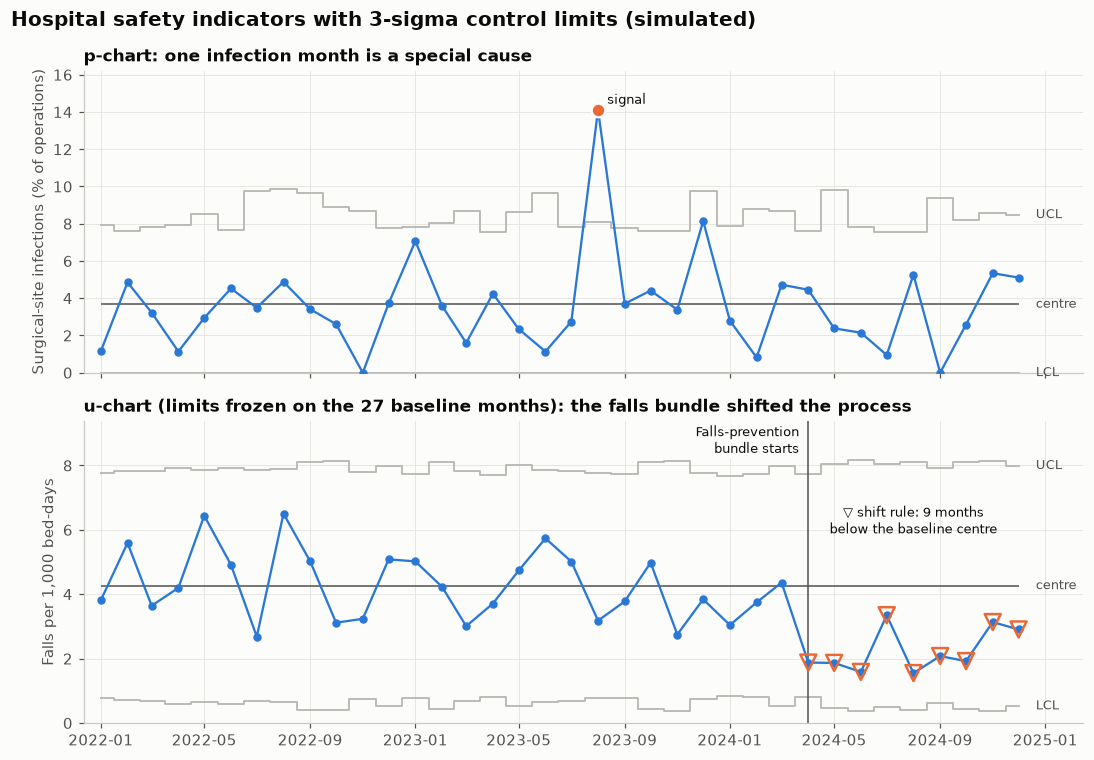

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, chart, value, scale, label in (
        (a1, p, "p", 100, "Surgical-site infections (% of operations)"),
        (a2, u, "u", 1000, "Falls per 1,000 bed-days")):
    v = chart[value] * scale
    ax.step(months, chart["ucl"] * scale, where="mid", color="#b8b7b1", linewidth=1.2)
    ax.step(months, chart["lcl"] * scale, where="mid", color="#b8b7b1", linewidth=1.2)
    ax.hlines(chart["center"].iloc[0] * scale, months[0], months[-1], color="#52514e", linewidth=1)
    ax.plot(months, v, color=PALETTE[0], marker="o", markersize=4.5, linewidth=1.5, zorder=3)
    sig = chart["signal"].values
    ax.scatter(months[sig], v[sig], s=80, color=PALETTE[1], edgecolor="#fcfcfb", linewidth=1.5, zorder=4)
    for m, val in zip(months[sig], v[sig]):
        ax.annotate("signal", (m, val), xytext=(6, 4), textcoords="offset points", fontsize=8.5,
                    color="#0b0b0b")
    label_x = months[-1] + np.timedelta64(20, "D")
    for key, text in (("center", "centre"), ("ucl", "UCL"), ("lcl", "LCL")):
        ax.text(label_x, chart[key].iloc[-1] * scale, text, va="center", fontsize=8.5, color="#52514e")
    ax.set_ylabel(label)
    ax.set_ylim(0, max(chart["ucl"].max() * scale, v.max()) * 1.15)
    ax.set_xlim(months[0] - np.timedelta64(20, "D"), months[-1] + np.timedelta64(75, "D"))
a1.set_title("p-chart: one infection month is a special cause", fontsize=11)
a2.set_title("u-chart (limits frozen on the 27 baseline months): the falls bundle shifted the process", fontsize=11)
a2.scatter(months[falls_shift], u["u"].values[falls_shift] * 1000, s=110, marker="v", facecolor="none",
           edgecolor=PALETTE[1], linewidth=1.6, zorder=5)
a2.text(months[31], ubar * 1000 * 1.35, f"▽ shift rule: {len(falls_shift)} months\nbelow the baseline centre",
        ha="center", va="bottom", fontsize=8.5)
a2.axvline(months[change], color="#52514e", linewidth=1)
a2.annotate("Falls-prevention\nbundle starts", (months[change], a2.get_ylim()[1]), xytext=(-6, -2),
            textcoords="offset points", fontsize=8.5, ha="right", va="top",
            bbox=dict(boxstyle="square,pad=0.15", fc="#fcfcfb", ec="none"))
fig.suptitle("Hospital safety indicators with 3-sigma control limits (simulated)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## How to read it

The infection proportion stays inside its stepped limits except for one month above the upper limit: a special cause (here, a simulated outbreak) worth investigating. The falls rate is stable until the prevention bundle starts. No single later month is below the lower limit, but every month after the change sits below the frozen baseline centre line (triangles), which the 8-point shift rule flags as a real, sustained improvement.

## Reference

This method comes from the research literature:

- Mohammed, M. A., Worthington, P. & Woodall, W. H. (2008). Plotting basic control charts: tutorial notes for healthcare practitioners. Quality and Safety in Health Care 17(2), 137–145. <https://qualitysafety.bmj.com/content/17/2/137>

---
Standalone script: [`spc_control_chart.py`](spc_control_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)